![Banner](../images/09_capstones.png)

# Groundwater Arsenic Risk in Bangladesh

**A geostatistical capstone: from well samples to exceedance probability maps and a district priority list**

This is Capstone 1 of the geostatistics module (Part 9). Chapters 05_01 to 05_08 teach one method per notebook. This notebook starts from an applied question and uses the methods the question needs: variogram modeling, ordinary kriging, indicator kriging, disjunctive kriging, soft (Markov-Bayes) kriging and sequential indicator simulation.

**Dataset:** National Hydrochemical Survey of Bangladesh, BGS and DPHE (`Data/00_shared/data_geostatistics/BGS_BD/bgs_geochemical.csv`, 3,534 tube wells sampled in 1998 and 1999), a 5 km prediction grid (`bd_grid.csv`) and the national boundary (`BD_Banladesh_BUTM.shp`).

**Target:** Arsenic in groundwater (`As`, µg/L)

**Library:** `geolattice.geostatistics`

## Overview

> Where does arsenic in tube-well water exceed the drinking-water limits, and how certain is that classification?

Two limits matter. The WHO guideline value is **10 µg/L**. The Bangladesh drinking-water standard is **50 µg/L**. A map of the predicted concentration alone does not answer the question, because a predicted value of 40 µg/L with a large error is not a safe well. What a water-supply planner needs is the **probability that a new well at a given location exceeds the limit**.

### Objectives

| Objective | Question | Sections |
|---|---|---|
| 1. Describe the data | How is arsenic distributed, how many values are below the detection limit, and how does it change with well depth? | 1 to 3 |
| 2. Model spatial continuity | Over what distance are arsenic values related, and how much variation is purely local? | 4 and 5 |
| 3. Compare predictors | Do lognormal kriging, indicator kriging and disjunctive kriging give different exceedance probabilities on wells held out from the model? | 6 and 7 |
| 4. Use secondary information | Can routine hydrochemistry (phosphorus, iron) replace part of the arsenic assays? | 8 |
| 5. Map risk and its uncertainty | Where is the probability of exceeding 10 and 50 µg/L high, and how wide is the uncertainty on the affected area? | 9 and 10 |
| 6. Support a decision | Which districts should be tested and mitigated first, and is the deep aquifer a safe alternative? | 11 and 12 |

## API overview

```
- geopandas / pyproj            -> projection to BUTM, national boundary
- declus_cell                   -> cell declustering weights
- Variogram, OrdinaryKriging    -> lognormal kriging of log(As)
- fit_indicator_variogram       -> indicator variograms at seven cutoffs
- IndicatorKriging, IndicatorKrigingCV, compute_etype_from_probabilities
- DisjunctiveKriging            -> Hermite-polynomial exceedance probability
- SoftKriging, markov_bayes_calibrate -> Markov-Bayes kriging with soft data
- sisim                         -> sequential indicator simulation
- sklearn: train_test_split, LogisticRegression, roc_auc_score, brier_score_loss
```

## Setup

**Installation.** This notebook needs installation option 4 (core, spatial analysis, spatial statistics and geostatistics): `pip install "geolattice[geostats]"`. See "Installation options" in the GeoLattice README.

In [1]:
%matplotlib inline
import sys, time, warnings
warnings.filterwarnings("ignore")
# Keep TensorFlow out of this process (optional regression-kriging backends).
sys.modules.setdefault("tensorflow", None)

# Scientific stack, scoring tools, and the geostatistics estimators used below.
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from scipy.optimize import minimize
from scipy.spatial import cKDTree
from scipy.stats import norm
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import geolattice.geostatistics as gstat
from geolattice.geostatistics import (
    Variogram,
    OrdinaryKriging,
    IndicatorKriging,
    IndicatorKrigingCV,
    DisjunctiveKriging,
    SoftKriging,
    fit_indicator_variogram,
    compute_etype_from_probabilities,
    markov_bayes_calibrate,
    declus_cell,
    sisim,
)
from geolattice.geostatistics.utils.backend import cupy_gpu_usable

# Plot style and a fixed seed for the split, the variogram subsamples, and the simulations.
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
SEED = 42
np.random.seed(SEED)

# cupy_gpu_usable() runs a real kernel, so an installed but unusable CuPy stays on CPU.
USE_GPU = cupy_gpu_usable()
print("geolattice.geostatistics :", gstat.__version__)
print("Backend             :", "GPU (CuPy)" if USE_GPU else "CPU (NumPy)")

# Regulatory cutoffs for exceedance rates, indicator models, and the risk maps.
WHO_LIMIT = 10.0   # µg/L, WHO guideline value
BD_LIMIT = 50.0    # µg/L, Bangladesh drinking-water standard

geolattice.geostatistics : 0.3.49
Backend             : GPU (CuPy)


## Data

The survey sampled about one well per 37 km² across the country, excluding the Chittagong Hill Tracts. Each record has the well location, depth, type and year of construction, and the concentration of arsenic and 19 other analytes. Arsenic is reported in µg/L and the other analytes in mg/L.

In [2]:
# Walk up from the working directory until the BGS Bangladesh tables are found.
ROOT = Path.cwd().resolve()
while not (ROOT / "Data" / "00_shared" / "data_geostatistics" / "BGS_BD" / "bgs_geochemical.csv").is_file():
    if ROOT.parent == ROOT:
        raise FileNotFoundError(
            "Could not find Data/00_shared/data_geostatistics/BGS_BD/bgs_geochemical.csv. "
            "Run this notebook from the GeoLattice repository."
        )
    ROOT = ROOT.parent
DATA_DIR = ROOT / "Data" / "00_shared" / "data_geostatistics" / "BGS_BD"

# Well chemistry, the national prediction grid, and the country boundary.
raw = pd.read_csv(DATA_DIR / "bgs_geochemical.csv")
grid = pd.read_csv(DATA_DIR / "bd_grid.csv")
bd = gpd.read_file(DATA_DIR / "BD_Banladesh_BUTM.shp")

print(f"Wells: {len(raw):,}    Columns: {raw.shape[1]}    Grid nodes: {len(grid):,}")
print("Boundary CRS:", bd.crs.name)
print("Sampling dates:", raw["SAMPLE_DATE"].str[-4:].value_counts().sort_index().to_dict())
raw[["SAMPLE_ID", "LONG_DEG", "LAT_DEG", "WELL_TYPE", "WELL_DEPTH", "DIVISION", "DISTRICT", "As", "Fe", "Mn", "P_", "SO4"]].head()

Wells: 3,534    Columns: 34    Grid nodes: 5,339
Boundary CRS: Bangladesh Universal Tranverse Mercator (BUTM_2010)
Sampling dates: {'1998': 2039, '1999': 1495}


,SAMPLE_ID,LONG_DEG,LAT_DEG,WELL_TYPE,WELL_DEPTH,DIVISION,DISTRICT,As,Fe,Mn,P_,SO4
0,S98_02701,90.093,22.372,DTW,322.0,Barisal,Jhalakati,0.5,0.103,0.182,2.6,< 0.2
1,S98_02715,89.410,23.942,STW,42.0,Rajshahi,Pabna,0.5,0.087,1.79,0.4,< 0.2
2,S98_02979,91.603,24.572,STW,38.0,Sylhet,Habiganj,0.5,1.37,0.146,0.3,< 0.2
3,S98_02992,91.175,23.791,STW,20.0,Chittagong,Brahamanbaria,0.5,0.128,0.023,< 0.2,2.5
4,S98_03108,89.555,22.811,DTW,310.0,Khulna,Khulna,0.5,0.019,0.027,< 0.2,< 0.2


## Cleaning and preparation

Four steps.

1. **Censored values.** Results below the detection limit are stored as text such as `< 0.04` for the co-analytes. They are replaced by half the detection limit and flagged. Arsenic is already numeric in this file. The lowest value, 0.25 µg/L, is repeated in many records, which is consistent with a 0.5 µg/L detection limit that has already been replaced by half its value.
2. **Projection.** Longitude and latitude are projected to the Bangladesh Universal Transverse Mercator system used by the grid and the boundary. Coordinates are kept in kilometres so that variogram ranges are easy to read.
3. **Depth class.** Wells are split at 150 m, the depth BGS used to separate the shallow aquifer from the deep aquifer.
4. **Duplicate locations.** Wells that share the same coordinates give a singular kriging system. They are merged within each depth class using the median.

In [3]:
def censored_to_numeric(series):
    # Parse a column that mixes numbers and '< DL' strings. Returns (values, censored flag).
    txt = series.astype(str).str.strip()
    cens = txt.str.startswith("<")
    val = pd.to_numeric(txt.str.replace("<", "", regex=False).str.strip(), errors="coerce")
    return np.where(cens, val / 2.0, val), cens.to_numpy()

# Substitute half the detection limit for values stored as '< DL', and count how often that happens.
df = raw.copy()
PROXIES = {"Fe": "Fe", "Mn": "Mn", "P_": "P", "SO4": "SO4"}
cens_rows = []
for col, name in PROXIES.items():
    df[name], flag = censored_to_numeric(raw[col])
    cens_rows.append({"analyte": name, "unit": "mg/L", "n_censored": int(flag.sum()),
                      "pct_censored": 100 * flag.mean(), "n_missing": int(np.isnan(df[name]).sum())})

# Arsenic is already numeric. The smallest reported value is treated as the detection limit.
AS_FLOOR = float(df["As"].min())
df["As_censored"] = df["As"] <= AS_FLOOR
cens_rows.insert(0, {"analyte": "As", "unit": "µg/L", "n_censored": int(df["As_censored"].sum()),
                     "pct_censored": 100 * df["As_censored"].mean(), "n_missing": int(df["As"].isna().sum())})
display(pd.DataFrame(cens_rows).round(1))

# Projection to BUTM (metres), then kilometres
pts = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["LONG_DEG"], df["LAT_DEG"]), crs=4326).to_crs(bd.crs)
df["x"] = pts.geometry.x / 1000.0
df["y"] = pts.geometry.y / 1000.0

# Depth class
DEPTH_SPLIT = 150.0
df["aquifer"] = np.where(df["WELL_DEPTH"] >= DEPTH_SPLIT, "deep (>= 150 m)", "shallow (< 150 m)")

# National outline in kilometres, for plotting
outline = gpd.GeoSeries([bd.union_all()], crs=bd.crs).scale(0.001, 0.001, origin=(0, 0))
inside = pts.within(bd.union_all()).mean()
print(f"Lowest arsenic value (taken as half the detection limit): {AS_FLOOR} µg/L")
print(f"Wells inside the national boundary: {inside:.1%}")
print(f"Wells sharing coordinates with another well: {df.duplicated(['x', 'y'], keep=False).sum()}")

,analyte,unit,n_censored,pct_censored,n_missing
0,As,µg/L,994,28.1,0
1,Fe,mg/L,14,0.4,4
2,Mn,mg/L,25,0.7,4
3,P,mg/L,996,28.2,4
4,SO4,mg/L,844,23.9,4


Lowest arsenic value (taken as half the detection limit): 0.25 µg/L
Wells inside the national boundary: 99.0%
Wells sharing coordinates with another well: 227


In [4]:
# Collapse wells that share coordinates, keeping the median of each measurement.
def merge_duplicates(d):
    return (d.groupby(["x", "y"], as_index=False)
              .agg(As=("As", "median"), depth=("WELL_DEPTH", "median"),
                   Fe=("Fe", "median"), Mn=("Mn", "median"), P=("P", "median"), SO4=("SO4", "median"),
                   DIVISION=("DIVISION", "first"), DISTRICT=("DISTRICT", "first")))

# Shallow wells are the mapping target. Deep wells stay separate for the aquifer comparison.
shallow = merge_duplicates(df[df["aquifer"].str.startswith("shallow")])
deep = merge_duplicates(df[df["aquifer"].str.startswith("deep")])

# Log arsenic feeds the continuous variogram. Nearest-neighbour distance describes the sample spacing.
xy = shallow[["x", "y"]].to_numpy(float)
z = shallow["As"].to_numpy(float)
logz = np.log(z)

nn_dist = cKDTree(xy).query(xy, k=2)[0][:, 1]
print(f"Shallow wells after merging duplicates: {len(shallow):,}   Deep wells: {len(deep):,}")
print(f"Nearest-neighbour distance between shallow wells (km): "
      f"median {np.median(nn_dist):.1f}, 95th percentile {np.percentile(nn_dist, 95):.1f}")

Shallow wells after merging duplicates: 3,146   Deep wells: 327
Nearest-neighbour distance between shallow wells (km): median 3.2, 95th percentile 5.8


## Exploratory analysis

The summary below is the first decision-relevant result: the share of wells above each limit, by aquifer and by division.

In [5]:
# Well counts, concentration summaries, and the share of wells above each regulatory limit.
def exceed_summary(d, by):
    g = d.groupby(by)["As"]
    out = pd.DataFrame({
        "n_wells": g.size(),
        "median_As": g.median(),
        "mean_As": g.mean(),
        "max_As": g.max(),
        "pct_below_DL": g.apply(lambda s: 100 * (s <= AS_FLOOR).mean()),
        "pct_above_10": g.apply(lambda s: 100 * (s > WHO_LIMIT).mean()),
        "pct_above_50": g.apply(lambda s: 100 * (s > BD_LIMIT).mean()),
    })
    return out.round(1)

# National rates first, then the same summary by aquifer and by division for the shallow wells.
print("All wells:  "
      f"{100 * (df['As'] > WHO_LIMIT).mean():.1f}% above 10 µg/L,  "
      f"{100 * (df['As'] > BD_LIMIT).mean():.1f}% above 50 µg/L")
display(exceed_summary(df, "aquifer"))
display(exceed_summary(df[df["aquifer"].str.startswith("shallow")], "DIVISION").sort_values("pct_above_50", ascending=False))

All wells:  42.1% above 10 µg/L,  24.9% above 50 µg/L


,n_wells,median_As,mean_As,max_As,pct_below_DL,pct_above_10,pct_above_50
aquifer,,,,,,,
deep (>= 150 m),327,0.8,2.8,108.0,32.1,4.9,0.9
shallow (< 150 m),3207,6.1,60.5,1660.0,27.7,45.9,27.4


,n_wells,median_As,mean_As,max_As,pct_below_DL,pct_above_10,pct_above_50
DIVISION,,,,,,,
Chittagong,404,73.2,150.4,1090.0,9.4,66.1,55.4
Khulna,431,39.4,92.5,1660.0,16.0,68.4,44.8
Barisal,98,22.4,111.1,862.0,7.1,66.3,39.8
Dhaka,950,13.3,65.6,924.0,22.0,53.2,31.9
Sylhet,252,13.5,29.1,320.0,18.7,55.6,21.0
Rajshahi,1072,0.3,12.0,708.0,48.4,18.6,6.2


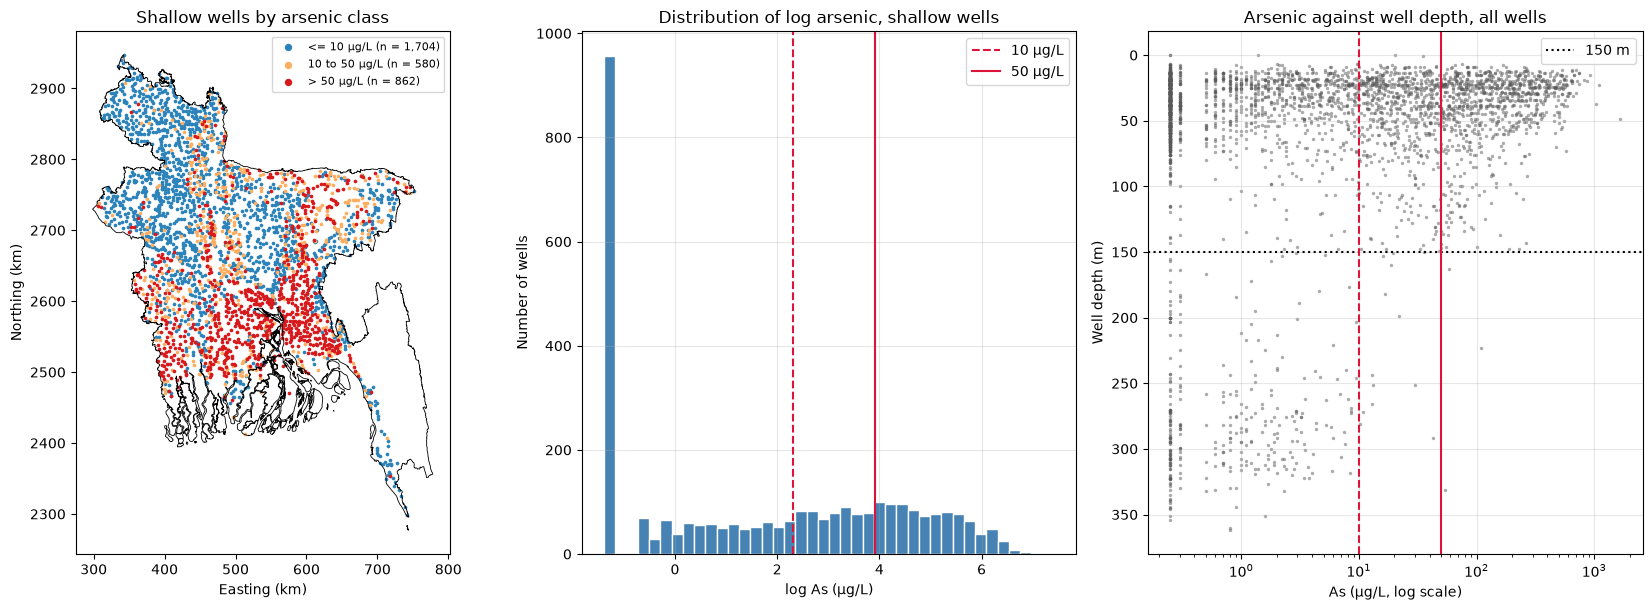

Skewness of As: 3.57   Skewness of log As: 0.12


In [6]:
# Three classes: at or below the WHO guideline, between the two standards, and above the Bangladesh limit.
CLASS_BINS = [0, WHO_LIMIT, BD_LIMIT, np.inf]
CLASS_LABELS = ["<= 10 µg/L", "10 to 50 µg/L", "> 50 µg/L"]
CLASS_COLORS = ["#2b83ba", "#fdae61", "#d7191c"]

# Shared map frame: national outline, equal aspect, and kilometre axes.
def base_map(ax, title=None):
    outline.boundary.plot(ax=ax, color="k", linewidth=0.6)
    ax.set_aspect("equal")
    ax.set_xlabel("Easting (km)")
    ax.set_ylabel("Northing (km)")
    ax.grid(False)
    if title:
        ax.set_title(title)

# Class map, histogram of log arsenic, and arsenic against well depth.
fig, axes = plt.subplots(1, 3, figsize=(17, 6.2))

# Shallow wells coloured by those three classes.
cls = pd.cut(shallow["As"], CLASS_BINS, labels=CLASS_LABELS, include_lowest=True)
for lab, col in zip(CLASS_LABELS, CLASS_COLORS):
    m = (cls == lab).to_numpy()
    axes[0].scatter(xy[m, 0], xy[m, 1], s=7, c=col, label=f"{lab} (n = {m.sum():,})", linewidths=0)
base_map(axes[0], "Shallow wells by arsenic class")
axes[0].legend(loc="upper right", fontsize=8, markerscale=2)

# Log scale, so both regulatory limits are visible on a strongly right-skewed distribution.
axes[1].hist(logz, bins=40, color="steelblue", edgecolor="white")
for lim, ls in [(WHO_LIMIT, "--"), (BD_LIMIT, "-")]:
    axes[1].axvline(np.log(lim), color="crimson", ls=ls, label=f"{lim:.0f} µg/L")
axes[1].set_title("Distribution of log arsenic, shallow wells")
axes[1].set_xlabel("log As (µg/L)")
axes[1].set_ylabel("Number of wells")
axes[1].legend()

# Depth increases downward. The dotted line is the 150 m split between the shallow and deep aquifers.
axes[2].scatter(df["As"], df["WELL_DEPTH"], s=6, c="0.35", alpha=0.5, linewidths=0)
axes[2].axhline(DEPTH_SPLIT, color="k", ls=":", label="150 m")
axes[2].axvline(WHO_LIMIT, color="crimson", ls="--")
axes[2].axvline(BD_LIMIT, color="crimson", ls="-")
axes[2].set_xscale("log")
axes[2].invert_yaxis()
axes[2].set_title("Arsenic against well depth, all wells")
axes[2].set_xlabel("As (µg/L, log scale)")
axes[2].set_ylabel("Well depth (m)")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"Skewness of As: {pd.Series(z).skew():.2f}   Skewness of log As: {pd.Series(logz).skew():.2f}")

**Reading the results.** Across all 3,534 wells, 42.1% exceed the WHO guideline and 24.9% exceed the Bangladesh standard. The problem is concentrated in the shallow aquifer: 45.9% and 27.4% of shallow wells exceed the two limits, against 4.9% and 0.9% of deep wells. The regional contrast is just as strong. More than half of the shallow wells in Chittagong division exceed 50 µg/L (55.4%), against 6.2% in Rajshahi division.

The log transform removes the skewness (3.57 to 0.12), but the histogram is not Gaussian. About 28% of the samples sit in one spike at the detection limit. Any method that assumes normality of log arsenic is working with a distribution that has a point mass in its lower tail.

### Declustering

Wells are denser in some regions than in others. If dense regions also have higher or lower arsenic, the plain average of the samples is a biased estimate of the national proportion. Cell declustering (`declus_cell`) gives each well a weight inversely proportional to the number of wells in its cell. The result depends on the cell size, so several sizes are compared.

In [7]:
# Cell declustering down-weights wells in dense clusters, so national means are not pulled toward heavily sampled areas.
span_x, span_y = np.ptp(xy[:, 0]), np.ptp(xy[:, 1])
rows = [{"cells": "none (equal weights)", "cell_size_km": np.nan, "mean_As": z.mean(),
         "pct_above_10": 100 * (z > WHO_LIMIT).mean(), "pct_above_50": 100 * (z > BD_LIMIT).mean()}]
for n_cells in [5, 10, 15, 20, 30]:
    w = declus_cell(xy[:, 0], xy[:, 1], nx=n_cells)
    rows.append({"cells": f"{n_cells} x {n_cells}", "cell_size_km": max(span_x, span_y) / n_cells,
                 "mean_As": np.average(z, weights=w),
                 "pct_above_10": 100 * np.average(z > WHO_LIMIT, weights=w),
                 "pct_above_50": 100 * np.average(z > BD_LIMIT, weights=w)})
display(pd.DataFrame(rows).round(1))

# A 20 by 20 grid supplies the weights used later as the target distribution of the simulations.
N_DECLUS = 20
w_declus = declus_cell(xy[:, 0], xy[:, 1], nx=N_DECLUS)

,cells,cell_size_km,mean_As,pct_above_10,pct_above_50
0,none (equal weights),NaN,60.5,45.8,27.4
1,5 x 5,129.7,55.2,51.4,24.6
2,10 x 10,64.8,53.1,46.2,24.6
3,15 x 15,43.2,55.2,46.6,26.6
4,20 x 20,32.4,57.6,46.0,26.1
5,30 x 30,21.6,58.1,45.0,26.0


**Reading the results.** Declustering changes the national estimates only slightly. The share above 50 µg/L moves between 24.6% and 26.6% depending on the cell size, against 27.4% with equal weights, so the survey is close to spatially balanced. The 20 x 20 weights (cells of about 32 km) are kept: 46.0% above 10 µg/L and 26.1% above 50 µg/L. These weights define the target distribution for the simulation in Section 10.

## Variogram of log arsenic

The variogram of log arsenic shows how fast similarity between wells decays with distance. Five models are fitted to the same experimental variogram and compared by their residual sum of squares. Directional variograms are then computed in four directions to check for anisotropy.

In [8]:
# Omnidirectional variogram of log arsenic. Pairs beyond 150 km are left out of the fit.
MAXLAG = 150.0   # km
N_LAGS = 15

# Fit spherical, exponential, Gaussian, Matern, and stable models, and rank them by residual sum of squares.
fits = []
vg_models = {}
for model in ["spherical", "exponential", "gaussian", "matern", "stable"]:
    vg = Variogram(xy, logz, model=model, maxlag=MAXLAG, n_lags=N_LAGS, use_gpu=USE_GPU)
    vg.fit()
    obs = np.asarray(vg.experimental, dtype=float)
    ok = np.isfinite(obs)
    pred = np.asarray(vg(vg.lags), dtype=float)
    p = np.asarray(vg.fitted_params, dtype=float)
    fits.append({"model": model, "nugget": p[0], "partial_sill": p[1], "range_km": p[2],
                 "nugget_share": p[0] / (p[0] + p[1]), "RSS": float(np.sum((pred[ok] - obs[ok]) ** 2))})
    vg_models[model] = vg
fit_tbl = pd.DataFrame(fits).sort_values("RSS").reset_index(drop=True)
display(fit_tbl.round(3))
print(f"Sample variance of log As: {logz.var():.2f}")

,model,nugget,partial_sill,range_km,nugget_share,RSS
0,stable,2.136,4.844,55.248,0.306,0.044
1,matern,2.115,4.514,74.993,0.319,0.051
2,exponential,2.699,3.708,48.466,0.421,0.079
3,spherical,3.057,3.016,107.261,0.503,0.430
4,gaussian,3.351,2.677,48.165,0.556,0.619


Sample variance of log As: 6.82


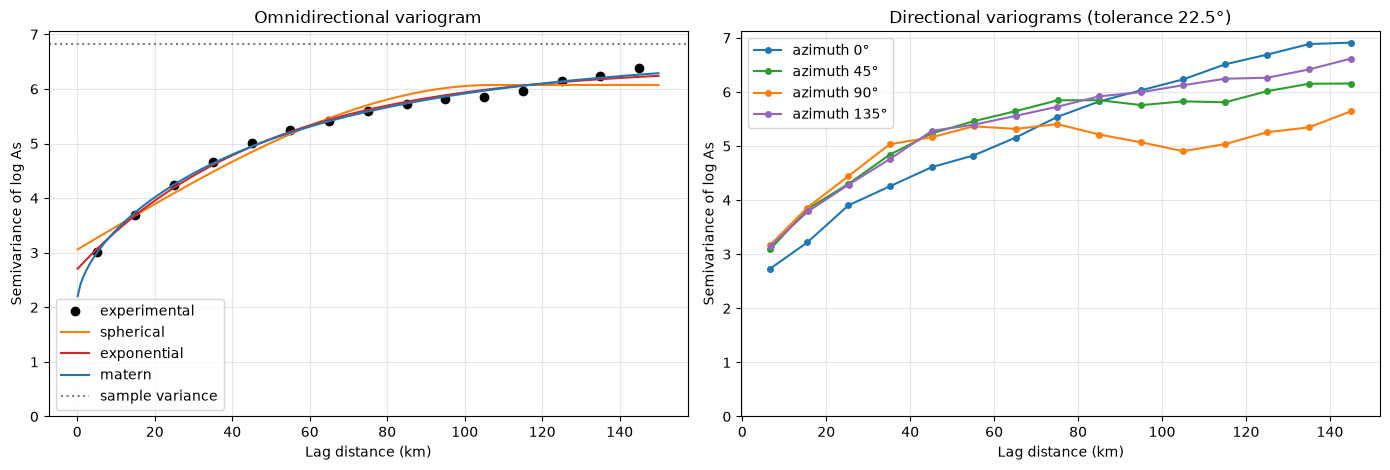

In [9]:
def directional_variogram(coords, values, azimuth, tol=22.5, maxlag=MAXLAG, n_lags=N_LAGS, max_points=2000, seed=SEED):
    # Experimental semivariogram for pairs whose direction is within `tol` degrees of `azimuth`
    # (degrees clockwise from north).
    rng = np.random.default_rng(seed)
    idx = rng.choice(len(values), size=min(max_points, len(values)), replace=False)
    c, v = coords[idx], values[idx]
    i, j = np.triu_indices(len(v), k=1)
    dx, dy = c[j, 0] - c[i, 0], c[j, 1] - c[i, 1]
    h = np.hypot(dx, dy)
    ang = np.degrees(np.arctan2(dx, dy)) % 180.0
    diff = np.abs(ang - azimuth % 180.0)
    keep = (np.minimum(diff, 180.0 - diff) <= tol) & (h <= maxlag) & (h > 0)
    edges = np.linspace(0, maxlag, n_lags + 1)
    b = np.digitize(h[keep], edges) - 1
    sq = 0.5 * (v[i][keep] - v[j][keep]) ** 2
    lag = np.array([h[keep][b == k].mean() if np.any(b == k) else np.nan for k in range(n_lags)])
    gam = np.array([sq[b == k].mean() if np.any(b == k) else np.nan for k in range(n_lags)])
    return lag, gam

# Exponential is close to the lowest residual sum of squares and has one fewer parameter, so later kriging uses it.
best_model = "exponential"
vg_log = vg_models[best_model]
h_fine = np.linspace(0.1, MAXLAG, 200)

# Omnidirectional experimental variogram, three fitted models, and the sample variance of log arsenic.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(vg_log.lags, vg_log.experimental, "o", color="k", label="experimental")
for model, color in [("spherical", "tab:orange"), ("exponential", "tab:red"), ("matern", "tab:blue")]:
    axes[0].plot(h_fine, vg_models[model](h_fine), color=color, label=model)
axes[0].axhline(logz.var(), color="0.5", ls=":", label="sample variance")
axes[0].set_ylim(bottom=0)
axes[0].set_xlabel("Lag distance (km)")
axes[0].set_ylabel("Semivariance of log As")
axes[0].set_title("Omnidirectional variogram")
axes[0].legend()

# Four azimuths, to judge whether a single isotropic range is reasonable.
for az, color in zip([0, 45, 90, 135], ["tab:blue", "tab:green", "tab:orange", "tab:purple"]):
    lag, gam = directional_variogram(xy, logz, az)
    axes[1].plot(lag, gam, "o-", ms=4, color=color, label=f"azimuth {az}°")
axes[1].set_ylim(bottom=0)
axes[1].set_xlabel("Lag distance (km)")
axes[1].set_ylabel("Semivariance of log As")
axes[1].set_title("Directional variograms (tolerance 22.5°)")
axes[1].legend()
plt.tight_layout()
plt.show()

**Reading the results.** Three points stand out.

- **Large nugget.** With the exponential model the nugget is 2.70 and the partial sill 3.71, so about 42% of the modeled variance is present at the shortest lag. Neighbouring wells a few kilometres apart can differ by orders of magnitude. No interpolator can predict an individual well with confidence, which is the reason this notebook maps probabilities and not concentrations.
- **Long-range structure.** The remaining variance builds up over tens of kilometres and the variogram is still rising at 150 km, which reflects the regional contrast between the north-west and the south.
- **Mild anisotropy.** The east-west variogram (azimuth 90°) levels off beyond about 40 km, while the north-south variogram (azimuth 0°) starts lower and keeps rising. An isotropic model is kept here for simplicity. Exercise 3 tests an anisotropic alternative.

The stable and Matérn models have the lowest residual sum of squares, but the exponential model is close and has one parameter less, so it is used for lognormal and disjunctive kriging.

## Indicator variograms

A single variogram of log arsenic assumes that low and high values have the same spatial continuity. Indicator variograms drop that assumption. For each cutoff $z_k$ the data are coded as 1 above the cutoff and 0 below, and a separate variogram is modeled. Seven cutoffs are used: 1, 5, 10, 25, 50, 100 and 200 µg/L. The two regulatory limits are among them, and the others describe the rest of the distribution.

From this point on, 20% of the shallow wells are held out as a test set. Variogram models are fitted on the training wells only.

Training wells: 2,516    Test wells: 630


,cutoff_ug_L,p_exceed,p(1-p),nugget,partial_sill,range_km,nugget_share
0,1.0,0.635,0.232,0.136,0.080,80.586,0.630
1,5.0,0.516,0.250,0.140,0.091,103.108,0.607
2,10.0,0.459,0.248,0.137,0.091,114.514,0.601
3,25.0,0.358,0.230,0.123,0.094,141.361,0.569
4,50.0,0.277,0.200,0.108,0.090,167.335,0.546
5,100.0,0.183,0.149,0.085,0.069,189.115,0.551
6,200.0,0.101,0.090,0.062,0.030,131.958,0.673


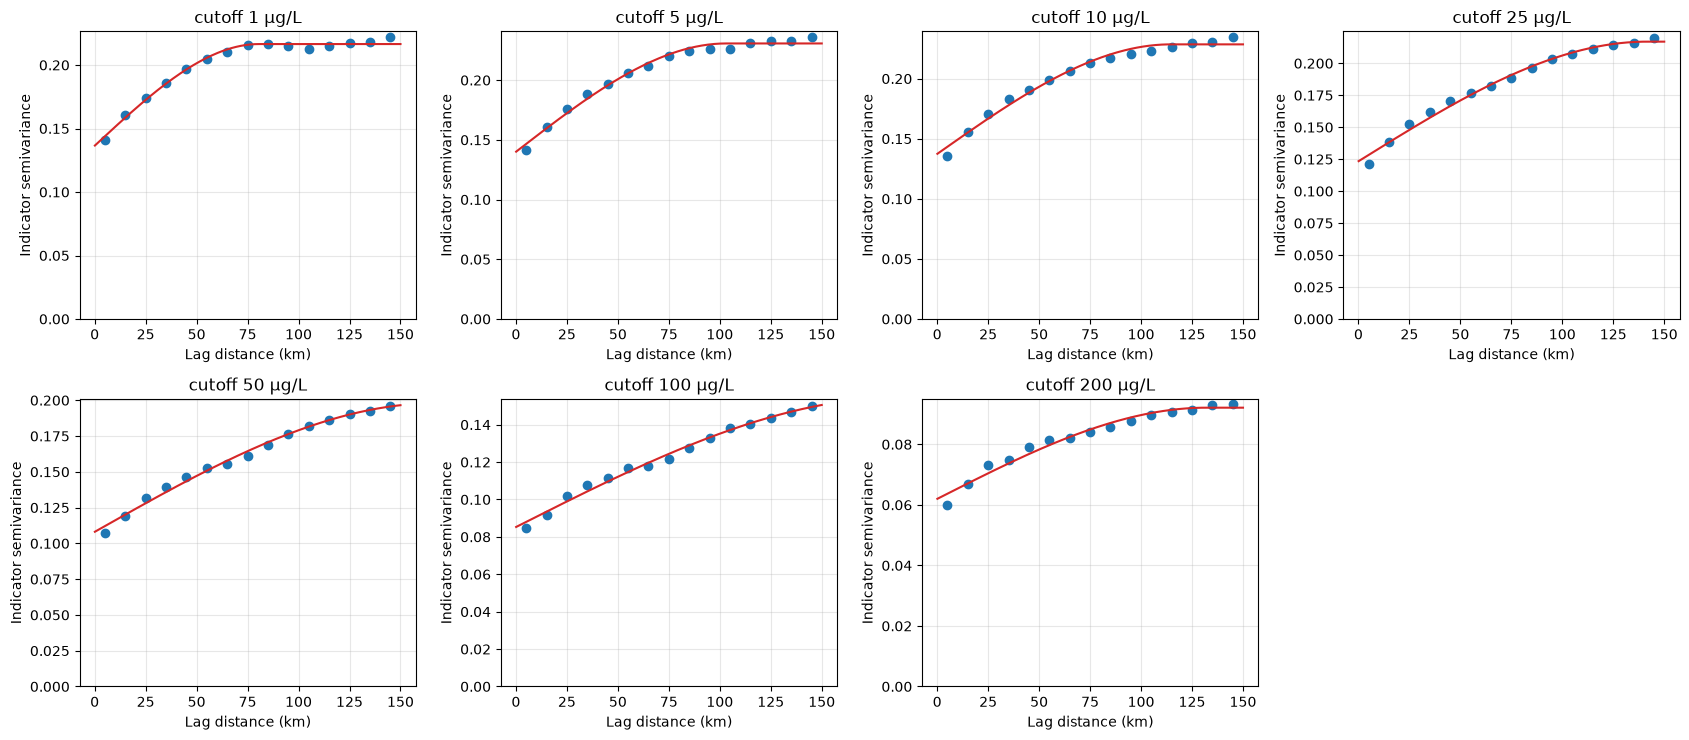

In [10]:
# Cutoffs from near the detection limit up to concentrations well above the Bangladesh standard.
THRESHOLDS = [1.0, 5.0, 10.0, 25.0, 50.0, 100.0, 200.0]

# Hold out 20% of the shallow wells. Variograms and kriging models are fit on the rest.
idx_train, idx_test = train_test_split(np.arange(len(z)), test_size=0.20, random_state=SEED)
xy_tr, xy_te = xy[idx_train], xy[idx_test]
z_tr, z_te = z[idx_train], z[idx_test]
print(f"Training wells: {len(z_tr):,}    Test wells: {len(z_te):,}")

# Spherical indicator model. The range is in kilometres, the same units as the coordinates.
def spherical(h, nugget, sill, rng):
    h = np.asarray(h, dtype=float)
    g = np.full_like(h, nugget + sill)
    m = h < rng
    hr = h[m] / rng
    g[m] = nugget + sill * (1.5 * hr - 0.5 * hr ** 3)
    return g

# One spherical indicator variogram per cutoff, fit to the experimental indicator semivariance.
def fit_indicator_models(coords, values, thresholds, maxlag=MAXLAG, n_lags=N_LAGS):
    params, empirical = {}, {}
    for t in thresholds:
        lags, gamma = fit_indicator_variogram(coords, values, threshold=t, maxlag=maxlag, n_lags=n_lags)
        p = float((values > t).mean())
        var_i = p * (1 - p)
        ok = np.isfinite(gamma)
        # Least squares from several starting ranges. The range is fitted in units of 100 km
        # so that the three parameters have a similar scale.
        loss = lambda q: np.sum((spherical(lags[ok], q[0], q[1], 100.0 * q[2]) - gamma[ok]) ** 2)
        fits_t = [minimize(loss, x0=[0.5 * var_i, 0.5 * var_i, r0],
                           bounds=[(0.0, 0.3), (1e-4, 0.3), (0.05, 4.0)], method="L-BFGS-B")
                  for r0 in (0.3, 0.6, 1.2, 2.4)]
        q = min(fits_t, key=lambda r: r.fun).x
        params[t] = (float(q[0]), float(q[1]), float(100.0 * q[2]))   # (nugget, partial sill, range in km)
        empirical[t] = (lags, gamma)
    return params, empirical

# Models for the training wells. Nugget share is the fraction of indicator variance with no spatial structure.
ivario, iemp = fit_indicator_models(xy_tr, z_tr, THRESHOLDS)
ivario_tbl = pd.DataFrame([
    {"cutoff_ug_L": t, "p_exceed": (z_tr > t).mean(), "p(1-p)": (z_tr > t).mean() * (1 - (z_tr > t).mean()),
     "nugget": ivario[t][0], "partial_sill": ivario[t][1], "range_km": ivario[t][2],
     "nugget_share": ivario[t][0] / (ivario[t][0] + ivario[t][1])}
    for t in THRESHOLDS])
display(ivario_tbl.round(3))

# Experimental indicator variogram and the fitted spherical model at each cutoff.
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5))
for ax, t in zip(axes.flat, THRESHOLDS):
    lags, gamma = iemp[t]
    ax.plot(lags, gamma, "o", color="tab:blue")
    ax.plot(h_fine, spherical(h_fine, *ivario[t]), "-", color="tab:red")
    ax.set_ylim(bottom=0)
    ax.set_title(f"cutoff {t:g} µg/L")
    ax.set_xlabel("Lag distance (km)")
    ax.set_ylabel("Indicator semivariance")
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

**Reading the results.** The nugget takes 55% to 67% of the indicator variance at every cutoff, which is higher than for log arsenic. Whether a well is above or below a limit is harder to predict from its neighbours than its order of magnitude. The range grows from about 80 km at 1 µg/L to about 190 km at 100 µg/L, so high values belong to broader regional structures than low values. A single variogram for all cutoffs would miss this difference.

## Three ways to estimate the exceedance probability

All three models are fitted on the training wells and evaluated on the test wells.

| Method | How the probability is obtained | Main assumption |
|---|---|---|
| Lognormal ordinary kriging | Krige log As, then $P(Z > z_k) = 1 - \Phi\big((\ln z_k - \hat y)/\sigma_K\big)$ | The kriging error of log As is Gaussian |
| Indicator kriging | Krige the 0/1 indicator at each cutoff with its own variogram | None on the distribution. One variogram per cutoff |
| Disjunctive kriging | Normal-score transform, expand the indicator in Hermite polynomials, krige each term | The transformed data are bivariate Gaussian |

Arsenic has many values at the detection limit. That spike breaks the Gaussian assumption of the first method at the low end. Indicator kriging does not need the values below a cutoff, only the fact that they are below it, so censored data are handled without any substitution.

In [11]:
# Three estimates of the exceedance probability at the test wells, with the time each one takes.
t0 = time.perf_counter()

# (a) Lognormal ordinary kriging
vg_tr = Variogram(xy_tr, np.log(z_tr), model=best_model, maxlag=MAXLAG, n_lags=N_LAGS, use_gpu=USE_GPU)
vg_tr.fit()
ok_model = OrdinaryKriging(vg_tr, use_gpu=USE_GPU).fit(xy_tr, np.log(z_tr))
ok_mean, ok_var = ok_model.predict(xy_te, return_variance=True)
ok_mean, ok_sd = np.asarray(ok_mean, float), np.sqrt(np.maximum(np.asarray(ok_var, float), 1e-12))
# Exceedance probability on the log scale, treating the kriging error as normal.
prob_ok = {t: 1.0 - norm.cdf((np.log(t) - ok_mean) / ok_sd) for t in THRESHOLDS}
t_ok = time.perf_counter() - t0

# (b) Indicator kriging
t0 = time.perf_counter()
# Up to 16 nearest training wells. The variogram parameters come from the fits above.
IK_KW = dict(cov_model="spherical", max_neighbors=16, use_gpu=USE_GPU)
ik_model = IndicatorKriging(**IK_KW).fit(xy_tr, z_tr)
prob_ik = ik_model.predict(xy_te, THRESHOLDS, ivario)
prob_ik = {t: np.clip(np.asarray(prob_ik[t], float), 0, 1) for t in THRESHOLDS}
t_ik = time.perf_counter() - t0

# (c) Disjunctive kriging
t0 = time.perf_counter()
# Twenty Hermite terms approximate the distribution of arsenic inside disjunctive kriging.
dk_model = DisjunctiveKriging(model=best_model, n_hermite=20, use_gpu=USE_GPU,
                              variogram_kwargs={"n_lags": N_LAGS, "maxlag": MAXLAG})
dk_model.fit(xy_tr, z_tr)
prob_dk = dk_model.predict_proba(xy_te, THRESHOLDS)
prob_dk = {t: np.asarray(prob_dk[t], float) for t in THRESHOLDS}
t_dk = time.perf_counter() - t0

print(f"Wall time (s):  lognormal OK {t_ok:.1f}   indicator kriging {t_ik:.1f}   disjunctive kriging {t_dk:.1f}")
print(f"Lognormal OK on the test wells: RMSE of log As = {np.sqrt(np.mean((ok_mean - np.log(z_te)) ** 2)):.2f} "
      f"(standard deviation of log As = {np.log(z_te).std():.2f})")

Wall time (s):  lognormal OK 0.3   indicator kriging 0.1   disjunctive kriging 2.4
Lognormal OK on the test wells: RMSE of log As = 1.70 (standard deviation of log As = 2.55)


## Validation on the held-out wells

Three scores are reported at the two regulatory limits.

- **AUC** measures ranking: the probability that a randomly chosen unsafe well receives a higher predicted probability than a randomly chosen safe well.
- **Brier score** is the mean squared error of the probability. The skill score compares it with a forecast that always predicts the national rate. Zero means no skill and 1 means perfect.
- **False-safe rate** is the share of wells that are truly above the limit but receive a probability below 0.5. This is the error that leaves people drinking contaminated water, so it matters more than the false-unsafe rate.

,limit_ug_L,method,AUC,Brier,Brier_skill,false_safe_rate,false_unsafe_rate
0,10.0,Lognormal ordinary kriging,0.877,0.149,0.400,0.318,0.122
1,10.0,Indicator kriging,0.878,0.141,0.429,0.234,0.177
2,10.0,Disjunctive kriging,0.874,0.144,0.419,0.297,0.145
3,50.0,Lognormal ordinary kriging,0.889,0.117,0.396,0.527,0.030
4,50.0,Indicator kriging,0.886,0.111,0.427,0.412,0.062
5,50.0,Disjunctive kriging,0.895,0.109,0.437,0.448,0.047


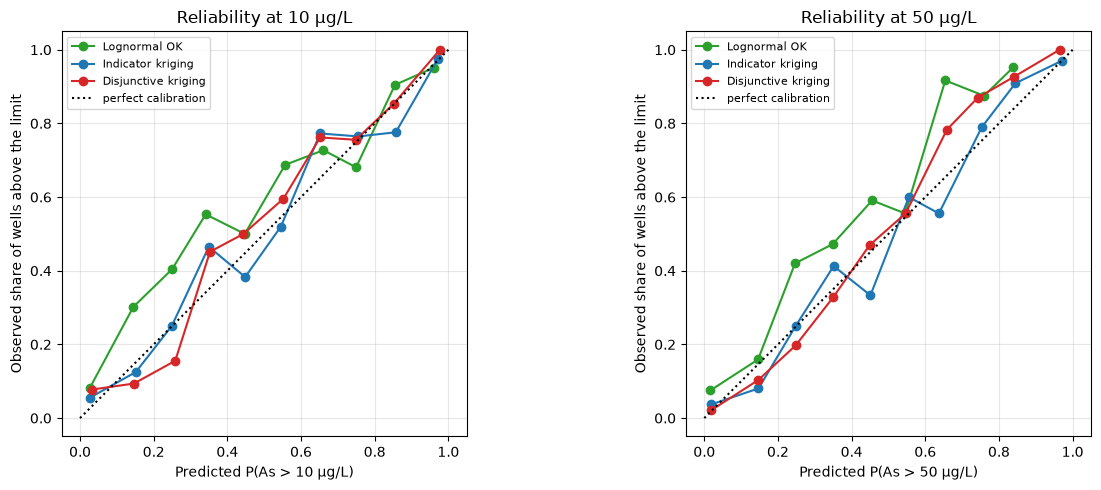

In [12]:
# AUC, Brier score, skill against a constant prediction, and the two misclassification rates at a probability of 0.5.
def score(y, p, cut=0.5):
    base = y.mean() * (1 - y.mean())
    brier = brier_score_loss(y, p)
    pred = p >= cut
    return {"AUC": roc_auc_score(y, p), "Brier": brier, "Brier_skill": 1 - brier / base,
            "false_safe_rate": float(np.mean(~pred[y == 1])), "false_unsafe_rate": float(np.mean(pred[y == 0]))}

# Score every method at the WHO guideline and at the Bangladesh standard.
rows = []
for lim in [WHO_LIMIT, BD_LIMIT]:
    y = (z_te > lim).astype(int)
    for name, probs in [("Lognormal ordinary kriging", prob_ok), ("Indicator kriging", prob_ik), ("Disjunctive kriging", prob_dk)]:
        rows.append({"limit_ug_L": lim, "method": name, **score(y, probs[lim])})
val_tbl = pd.DataFrame(rows)
display(val_tbl.round(3))

# Reliability diagram: mean predicted probability against the observed exceedance rate.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bins = np.linspace(0, 1, 11)
for ax, lim in zip(axes, [WHO_LIMIT, BD_LIMIT]):
    y = (z_te > lim).astype(int)
    for name, probs, color in [("Lognormal OK", prob_ok, "tab:green"), ("Indicator kriging", prob_ik, "tab:blue"), ("Disjunctive kriging", prob_dk, "tab:red")]:
        p = probs[lim]
        b = np.clip(np.digitize(p, bins) - 1, 0, 9)
        # Bins with fewer than 10 test wells are left out, so one well cannot swing the point.
        px = [p[b == k].mean() for k in range(10) if np.sum(b == k) >= 10]
        py = [y[b == k].mean() for k in range(10) if np.sum(b == k) >= 10]
        ax.plot(px, py, "o-", color=color, label=name)
    ax.plot([0, 1], [0, 1], "k:", label="perfect calibration")
    ax.set_xlabel(f"Predicted P(As > {lim:g} µg/L)")
    ax.set_ylabel("Observed share of wells above the limit")
    ax.set_title(f"Reliability at {lim:g} µg/L")
    ax.set_aspect("equal")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading the results.**

- **All three methods rank wells well and about equally.** AUC is between 0.87 and 0.90 at both limits. The data, not the method, set the ceiling.
- **Indicator and disjunctive kriging give better probabilities than lognormal kriging.** Their Brier skill is 0.42 to 0.44 against 0.40. The reliability plot shows why: lognormal kriging under-predicts in the middle of the range, where the observed share of unsafe wells is higher than the stated probability.
- **The false-safe rate is high for every method.** With a cut at P = 0.5, indicator kriging misses 23% of the wells above 10 µg/L and 41% of the wells above 50 µg/L. Lognormal kriging misses 53% at 50 µg/L. This follows from the large nugget: many contaminated wells sit in areas that look moderately safe.

The practical conclusion is that a kriged map can rank areas but cannot clear an individual well. Indicator kriging is used for the national maps because it is well calibrated, needs no assumption about the distribution, handles the censored values directly and runs in a fraction of a second.

### Five-fold cross-validation of indicator kriging at all cutoffs

The test set above is one random split. `IndicatorKrigingCV` repeats the exercise on five folds of all shallow wells and reports the Brier score at each cutoff.

In [13]:
# Refit the indicator models on every shallow well, then score indicator kriging with five-fold cross-validation.
ivario_all, _ = fit_indicator_models(xy, z, THRESHOLDS)
cv = IndicatorKrigingCV(n_splits=5, random_state=SEED)
cv_res = cv.validate(IndicatorKriging(**IK_KW), xy, z, THRESHOLDS, ivario_all)

# Brier skill is the gain over predicting the global exceedance rate at every well.
cv_tbl = pd.DataFrame({
    "cutoff_ug_L": THRESHOLDS,
    "IK_Brier": [cv_res["brier_scores"][t] for t in THRESHOLDS],
    "no_skill_Brier": [(z >= t).mean() * (1 - (z >= t).mean()) for t in THRESHOLDS],
})
cv_tbl["Brier_skill"] = 1 - cv_tbl["IK_Brier"] / cv_tbl["no_skill_Brier"]
display(cv_tbl.round(3))

,cutoff_ug_L,IK_Brier,no_skill_Brier,Brier_skill
0,1.0,0.148,0.229,0.353
1,5.0,0.148,0.250,0.407
2,10.0,0.139,0.248,0.441
3,25.0,0.127,0.229,0.445
4,50.0,0.111,0.199,0.442
5,100.0,0.083,0.146,0.427
6,200.0,0.061,0.090,0.329


**Reading the results.** Five-fold cross-validation confirms the single split. Brier skill is 0.41 to 0.45 between 5 and 100 µg/L and drops to about 0.33 to 0.35 at the two extreme cutoffs, where one class is rare or the cutoff is close to the detection limit.

## Can routine hydrochemistry stand in for arsenic assays?

Arsenic in the Bengal Basin is released when iron oxyhydroxides dissolve under reducing conditions, and the same process releases phosphorus and iron. Sulfate is low in strongly reducing water. These analytes are therefore possible **soft data** for arsenic.

The experiment below is a designed test of the Markov-Bayes method, not a field protocol. Suppose arsenic is assayed at only one quarter of the training wells (the hard data), while phosphorus, iron, manganese and sulfate are known at every well.

1. A logistic model calibrated on the hard wells converts the four analytes into a soft probability that As exceeds 50 µg/L.
2. `markov_bayes_calibrate` estimates the coefficient $B$ that scales the hard covariance into the hard-soft and soft-soft covariances.
3. `SoftKriging` combines the hard indicators and the soft probabilities.

Four predictors are compared on the same test wells: hard data only, soft probability only, Markov-Bayes kriging, and indicator kriging with arsenic at all training wells as the reference.

In [14]:
# Phosphate, iron, manganese, and sulphate stand in where an arsenic assay is withheld.
soft_cols = ["P", "Fe", "Mn", "SO4"]
has_soft = shallow[soft_cols].notna().all(axis=1).to_numpy()
print(f"Shallow wells with all four soft analytes: {has_soft.sum():,} of {len(shallow):,}")

# Log concentrations. The target indicator is exceedance of the Bangladesh standard.
X_soft = np.log(shallow[soft_cols].to_numpy(float))
ind50 = (z > BD_LIMIT).astype(float)

# A quarter of the training wells keep their arsenic assays. The rest are treated as soft data only.
tr = idx_train[has_soft[idx_train]]
te = idx_test[has_soft[idx_test]]
idx_hard, idx_softonly = train_test_split(tr, test_size=0.75, random_state=1)
print(f"Hard wells (As assayed): {len(idx_hard)}   Soft-only training wells: {len(idx_softonly)}   Test wells: {len(te)}")

# Strength of the association between log arsenic and each log analyte.
print("\nCorrelation of log As with each log analyte (shallow wells):")
print(pd.Series({c: np.corrcoef(X_soft[has_soft, k], logz[has_soft])[0, 1] for k, c in enumerate(soft_cols)}).round(2).to_string())

# 1. Soft probability from the hard wells only
soft_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_soft[idx_hard], ind50[idx_hard])
soft_hard = soft_model.predict_proba(X_soft[idx_hard])[:, 1]
idx_soft_all = np.r_[idx_softonly, te]                      # soft data exist at these wells, As withheld
soft_all = soft_model.predict_proba(X_soft[idx_soft_all])[:, 1]
soft_test = soft_model.predict_proba(X_soft[te])[:, 1]

# 2. Markov-Bayes calibration
B, corr_if, n_pairs = markov_bayes_calibrate(xy[idx_hard], ind50[idx_hard], xy[idx_hard], soft_hard)
B_diff = soft_hard[ind50[idx_hard] == 1].mean() - soft_hard[ind50[idx_hard] == 0].mean()
print(f"\nMarkov-Bayes B = {B:.3f}   corr(I, F) = {corr_if:.3f}   pairs = {n_pairs}")
print(f"E[F | I = 1] - E[F | I = 0] = {B_diff:.3f}")

# 3. Kriging: indicator variogram at 50 µg/L from the hard wells
iv_hard, _ = fit_indicator_models(xy[idx_hard], z[idx_hard], [BD_LIMIT])
nug50, sill50, rng50 = iv_hard[BD_LIMIT]

# B = 0 drops the soft neighbours, so this run uses the hard assays only.
sk_hard = SoftKriging(cov_model="spherical", max_neighbors_hard=16, max_neighbors_soft=0, use_gpu=USE_GPU)
sk_hard.fit(xy[idx_hard], ind50[idx_hard], xy[idx_soft_all], soft_all, B=0.0)
p_hard = np.clip(sk_hard.predict(xy[te], sill=sill50, range_=rng50, nugget=nug50), 0, 1)

sk_mb = SoftKriging(cov_model="spherical", max_neighbors_hard=16, max_neighbors_soft=16, use_gpu=USE_GPU)
sk_mb.fit(xy[idx_hard], ind50[idx_hard], xy[idx_soft_all], soft_all, B=B)
p_mb = np.clip(sk_mb.predict(xy[te], sill=sill50, range_=rng50, nugget=nug50), 0, 1)

p_full = np.clip(IndicatorKriging(**IK_KW).fit(xy[tr], z[tr]).predict(xy[te], [BD_LIMIT], {BD_LIMIT: ivario[BD_LIMIT]})[BD_LIMIT], 0, 1)

# Same test wells for hard-only kriging, the regression probability, soft kriging, and kriging with every arsenic assay.
y_te = ind50[te].astype(int)
soft_tbl = pd.DataFrame([
    {"predictor": f"Hard data only ({len(idx_hard)} As assays)", **score(y_te, p_hard)},
    {"predictor": "Soft probability only (P, Fe, Mn, SO4)", **score(y_te, soft_test)},
    {"predictor": "Markov-Bayes soft kriging", **score(y_te, p_mb)},
    {"predictor": f"Reference: indicator kriging, all {len(tr)} As assays", **score(y_te, p_full)},
])
display(soft_tbl.round(3))

Shallow wells with all four soft analytes: 3,142 of 3,146
Hard wells (As assayed): 628   Soft-only training wells: 1886   Test wells: 628

Correlation of log As with each log analyte (shallow wells):
P      0.72
Fe     0.64
Mn     0.05
SO4   -0.26

Markov-Bayes B = 0.983   corr(I, F) = 0.568   pairs = 628
E[F | I = 1] - E[F | I = 0] = 0.327


,predictor,AUC,Brier,Brier_skill,false_safe_rate,false_unsafe_rate
0,Hard data only (628 As assays),0.846,0.125,0.351,0.457,0.078
1,"Soft probability only (P, Fe, Mn, SO4)",0.857,0.130,0.327,0.354,0.125
2,Markov-Bayes soft kriging,0.855,0.131,0.322,0.360,0.129
3,"Reference: indicator kriging, all 2514 As assays",0.886,0.111,0.424,0.415,0.062


**Reading the results.**

- **Phosphorus and iron carry real information.** Log arsenic correlates at 0.72 with log phosphorus and 0.64 with log iron. The soft probability alone reaches an AUC of 0.857, slightly above kriging of 628 arsenic assays (0.846), and lowers the false-safe rate from 0.46 to 0.35. Its Brier score is slightly worse (0.130 against 0.125).
- **Markov-Bayes kriging does not improve on the soft probability here.** Its scores (AUC 0.855, Brier 0.131) are almost identical to the soft probability alone. The calibration returns $B = 0.98$, so the soft datum located at the prediction well is treated almost like a hard datum and dominates the estimate. `markov_bayes_calibrate` computes $B$ as $\mathrm{Cov}(I, F)/\mathrm{Var}(F)$, which is close to 1 for any well-calibrated probability. The difference of conditional means, $E[F \mid I=1] - E[F \mid I=0]$, is 0.33 on the same data.
- **Neither replaces the full survey.** Indicator kriging with arsenic at all training wells remains best (AUC 0.886, Brier 0.111).

One caveat on realism: a laboratory that measures phosphorus and iron in a water sample can measure arsenic in the same sample. The experiment shows how the method behaves with real covariates. It is more relevant where historical hydrochemical records exist without arsenic.

## National probability maps

Indicator kriging is now refitted on all shallow wells and applied to the 5 km grid. Two corrections are applied to the output.

- **Order relations.** Each cutoff is kriged separately, so the probabilities at one node are not guaranteed to decrease as the cutoff increases. They are forced to be non-increasing.
- **Unsampled areas.** Grid nodes more than 20 km from the nearest shallow well are masked. Most of them are in the Chittagong Hill Tracts and the Sundarbans, where the survey has no wells and the map would be an extrapolation.

Grid nodes: 5,339   mapped: 5,121   masked (> 20 km from a well): 218
Mapped area: 128,025 km²


Indicator kriging on the grid: 0.1 s   order-relation violations corrected: 7.9% of node-cutoff pairs


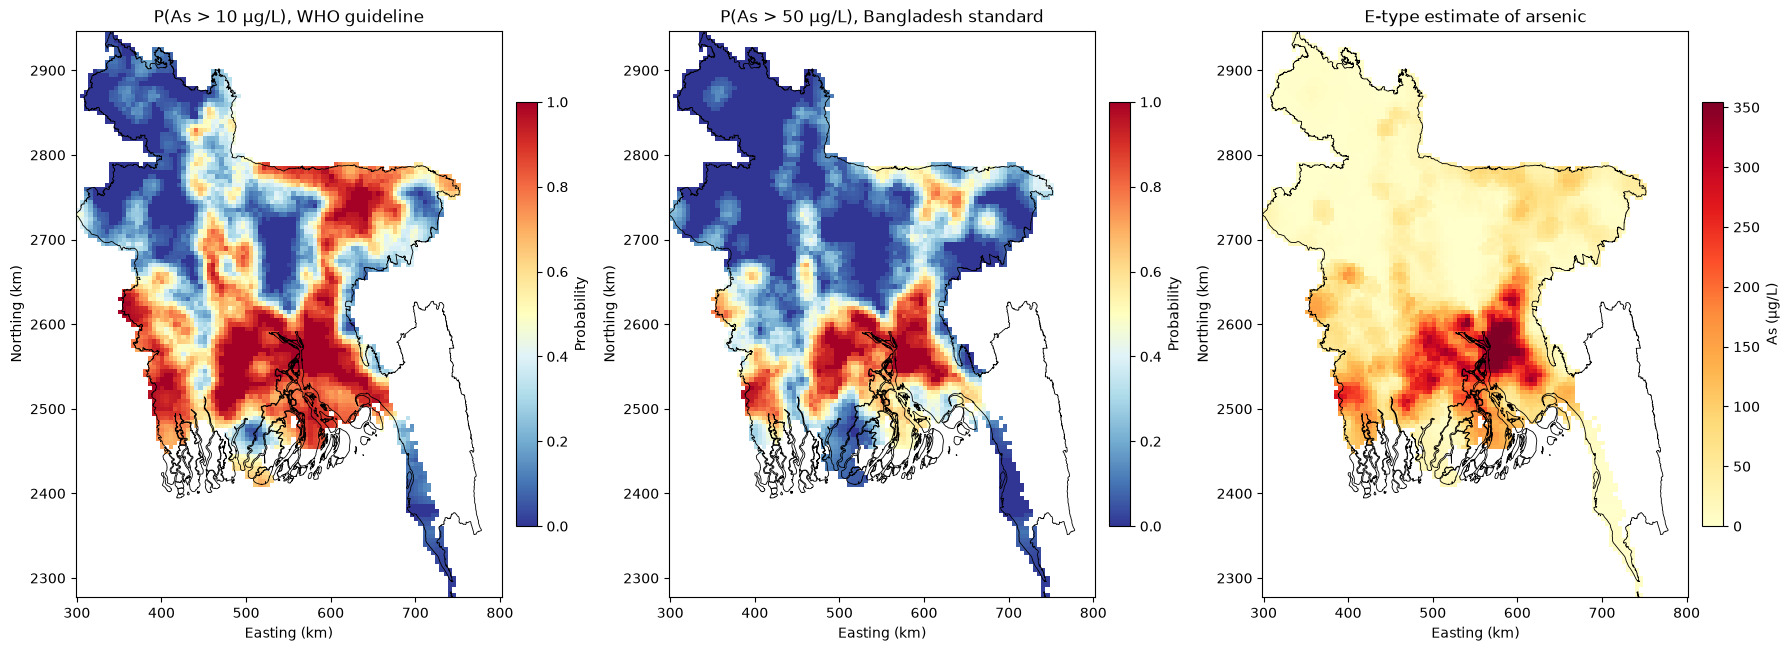

Mean probability over the mapped area:  P(As > 10) = 0.469   P(As > 50) = 0.274
E-type mean over the mapped area: 66.1 µg/L   declustered sample mean: 57.6 µg/L


In [15]:
# Grid coordinates in kilometres. Nodes more than 20 km from a shallow well are left unmapped.
gxy = grid[["x", "y"]].to_numpy(float) / 1000.0
CELL_KM = 5.0
MAX_DIST_KM = 20.0
dist_to_well = cKDTree(xy).query(gxy)[0]
mapped = dist_to_well <= MAX_DIST_KM
print(f"Grid nodes: {len(gxy):,}   mapped: {mapped.sum():,}   masked (> {MAX_DIST_KM:.0f} km from a well): {(~mapped).sum():,}")
print(f"Mapped area: {mapped.sum() * CELL_KM ** 2:,.0f} km²")

# Indicator kriging at every cutoff, with the models fit on all shallow wells.
t0 = time.perf_counter()
ik_full = IndicatorKriging(**IK_KW).fit(xy, z)
prob_grid = ik_full.predict(gxy, THRESHOLDS, ivario_all)
P = np.clip(np.vstack([np.asarray(prob_grid[t], float) for t in THRESHOLDS]), 0, 1)
# Probabilities must fall as the cutoff rises. Count the increases, then force a non-increasing sequence.
violations = np.mean(np.diff(P, axis=0) > 1e-9)
P = np.minimum.accumulate(P, axis=0)          # order-relation correction
P[:, ~mapped] = np.nan
print(f"Indicator kriging on the grid: {time.perf_counter() - t0:.1f} s   order-relation violations corrected: {100 * violations:.1f}% of node-cutoff pairs")

p10 = P[THRESHOLDS.index(WHO_LIMIT)]
p50 = P[THRESHOLDS.index(BD_LIMIT)]
# E-type concentration from the corrected probabilities. The upper tail stops at the 99.5th percentile of the wells.
etype = compute_etype_from_probabilities(THRESHOLDS, list(P), z_min=0.0, z_max=float(np.percentile(z, 99.5)))

# Regular raster for plotting
gx_u = np.sort(np.unique(gxy[:, 0]))
gy_u = np.sort(np.unique(gxy[:, 1]))
col = np.searchsorted(gx_u, gxy[:, 0])
row = np.searchsorted(gy_u, gxy[:, 1])

def to_raster(values):
    r = np.full((len(gy_u), len(gx_u)), np.nan)
    r[row, col] = values
    return r

# Place the node values on a regular raster and draw them with the national outline.
def plot_raster(ax, values, title, cmap="viridis", vmin=None, vmax=None, label="", norm=None):
    im = ax.pcolormesh(gx_u, gy_u, to_raster(values), cmap=cmap, vmin=vmin, vmax=vmax, norm=norm, shading="nearest")
    base_map(ax, title)
    if label is not None:
        plt.colorbar(im, ax=ax, label=label, fraction=0.046, pad=0.03)
    return im

# WHO probability, Bangladesh-standard probability, and the E-type concentration.
fig, axes = plt.subplots(1, 3, figsize=(18, 6.6))
plot_raster(axes[0], p10, f"P(As > {WHO_LIMIT:g} µg/L), WHO guideline", cmap="RdYlBu_r", vmin=0, vmax=1, label="Probability")
plot_raster(axes[1], p50, f"P(As > {BD_LIMIT:g} µg/L), Bangladesh standard", cmap="RdYlBu_r", vmin=0, vmax=1, label="Probability")
plot_raster(axes[2], etype, "E-type estimate of arsenic", cmap="YlOrRd", vmin=0, vmax=np.nanpercentile(etype, 99), label="As (µg/L)")
plt.tight_layout()
plt.show()

print(f"Mean probability over the mapped area:  P(As > 10) = {np.nanmean(p10):.3f}   P(As > 50) = {np.nanmean(p50):.3f}")
print(f"E-type mean over the mapped area: {np.nanmean(etype):.1f} µg/L   declustered sample mean: {np.average(z, weights=w_declus):.1f} µg/L")

### Risk classes

A probability map becomes a decision map once a risk tolerance is chosen. Three classes are used here for the Bangladesh standard.

| Class | Rule | Suggested action |
|---|---|---|
| Low risk | $P(\text{As} > 50) < 0.1$ | Routine monitoring |
| Uncertain | $0.1 \le P < 0.5$ | Test every well before use |
| High risk | $P \ge 0.5$ | Assume unsafe, prioritize alternative sources |

The thresholds are a policy choice. A more cautious planner would lower them.

,class,area_km2_at_50,area_km2_at_10,share_at_50_pct,share_at_10_pct
0,Low risk (P < 0.1),53625.0,28150.0,41.9,22.0
1,Uncertain (0.1 to 0.5),44900.0,39975.0,35.1,31.2
2,High risk (P >= 0.5),29500.0,59900.0,23.0,46.8


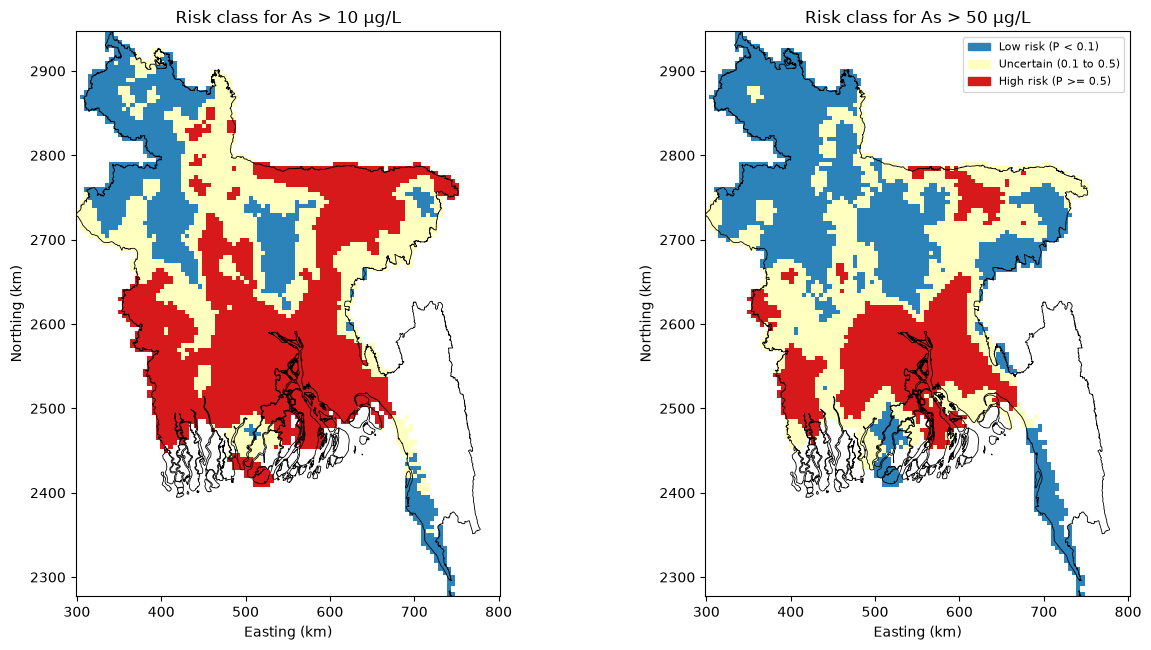

In [16]:
# Low, uncertain, and high risk. The upper edge sits just above 1 so a probability of 1 stays in the high class.
RISK_BINS = [0.0, 0.1, 0.5, 1.0000001]
RISK_LABELS = ["Low risk (P < 0.1)", "Uncertain (0.1 to 0.5)", "High risk (P >= 0.5)"]
RISK_COLORS = ["#2b83ba", "#ffffbf", "#d7191c"]

# Bin the finite probabilities. Unmapped nodes stay missing.
def risk_class(p):
    c = np.full(p.shape, np.nan)
    ok = np.isfinite(p)
    c[ok] = np.digitize(p[ok], RISK_BINS[1:-1])
    return c

# Area and share of each class at both regulatory limits.
risk50 = risk_class(p50)
risk10 = risk_class(p10)

area_tbl = pd.DataFrame({
    "class": RISK_LABELS,
    "area_km2_at_50": [np.sum(risk50 == k) * CELL_KM ** 2 for k in range(3)],
    "area_km2_at_10": [np.sum(risk10 == k) * CELL_KM ** 2 for k in range(3)],
})
area_tbl["share_at_50_pct"] = 100 * area_tbl["area_km2_at_50"] / area_tbl["area_km2_at_50"].sum()
area_tbl["share_at_10_pct"] = 100 * area_tbl["area_km2_at_10"] / area_tbl["area_km2_at_10"].sum()
display(area_tbl.round(1))

# The same three classes on the map, for the WHO guideline and the Bangladesh standard.
cmap_risk = ListedColormap(RISK_COLORS)
norm_risk = BoundaryNorm([-0.5, 0.5, 1.5, 2.5], cmap_risk.N)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.6))
for ax, r, lim in zip(axes, [risk10, risk50], [WHO_LIMIT, BD_LIMIT]):
    plot_raster(ax, r, f"Risk class for As > {lim:g} µg/L", cmap=cmap_risk, norm=norm_risk, label=None)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in RISK_COLORS]
axes[1].legend(handles, RISK_LABELS, loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

**Reading the results.** The maps reproduce the known pattern: a high-risk belt across the south and south-east (the lower Meghna and the Ganges delta), a second area in the north-east (the Sylhet basin) and low risk across the north-west and the uplifted Madhupur and Barind tracts.

For the Bangladesh standard, 23% of the mapped area (29,500 km²) is high risk and 42% is low risk. The remaining 35% is uncertain, and this is where well-by-well testing has the highest value. For the WHO guideline the high-risk share doubles to 47% and only 22% of the area is low risk.

## Uncertainty on the affected area: sequential indicator simulation

Kriged probabilities describe each node separately. They cannot say how uncertain the **total** affected area is, because that depends on how errors at neighbouring nodes move together. Sequential indicator simulation (`sisim`) generates many equally probable maps that honour the data, the declustered national distribution and the indicator variograms. Each realization gives one value of the affected area, and the spread across realizations is the uncertainty.

To keep the run time reasonable the simulation uses a 10 km grid (every second node in each direction) and 50 realizations.

In [17]:
# Fifty realizations on every other grid node, a 10 km spacing, so the sequential simulation stays tractable.
N_SIM = 50
sim_nodes = mapped & (col % 2 == 0) & (row % 2 == 0)
sim_xy = gxy[sim_nodes]
SIM_CELL_KM = 2 * CELL_KM
print(f"Simulation nodes: {sim_nodes.sum():,} on a {SIM_CELL_KM:.0f} km grid ({sim_nodes.sum() * SIM_CELL_KM ** 2:,.0f} km²)")

# Conditioning wells, and the declustered proportions the realizations should reproduce.
cond = pd.DataFrame({"x": xy[:, 0], "y": xy[:, 1], "As": z})
global_cdf = [float(np.average(z <= t, weights=w_declus)) for t in THRESHOLDS]
# sisim variogram format: [azimuth, nugget, major range, minor range, total sill, model]
vario_sis = {t: [0.0, ivario_all[t][0], ivario_all[t][2], ivario_all[t][2], ivario_all[t][0] + ivario_all[t][1], "spherical"]
             for t in THRESHOLDS}

# Search up to 16 neighbours within 60 km. Simulated values stay between the detection-limit floor and the sample maximum.
t0 = time.perf_counter()
sims = sisim(sim_xy, cond, "x", "y", "As", THRESHOLDS, global_cdf, vario_sis,
             num_points=16, radius=60.0, kriging_type="ordinary",
             zmin=AS_FLOOR, zmax=float(z.max()), utail="hyperbolic", utpar=1.5,
             nsim=N_SIM, seed=SEED, quiet=True)
sims = np.asarray(sims, float)
print(f"{sims.shape[0]} realizations x {sims.shape[1]} nodes in {(time.perf_counter() - t0) / 60:.1f} min")

pooled_cdf = [float(np.mean(sims <= t)) for t in THRESHOLDS]
display(pd.DataFrame({"cutoff_ug_L": THRESHOLDS, "target_cdf (declustered)": global_cdf, "simulated_cdf": pooled_cdf}).round(3))

Simulation nodes: 1,281 on a 10 km grid (128,100 km²)


50 realizations x 1281 nodes in 6.9 min


,cutoff_ug_L,target_cdf (declustered),simulated_cdf
0,1.0,0.367,0.362
1,5.0,0.481,0.475
2,10.0,0.540,0.532
3,25.0,0.664,0.643
4,50.0,0.739,0.726
5,100.0,0.837,0.825
6,200.0,0.904,0.903


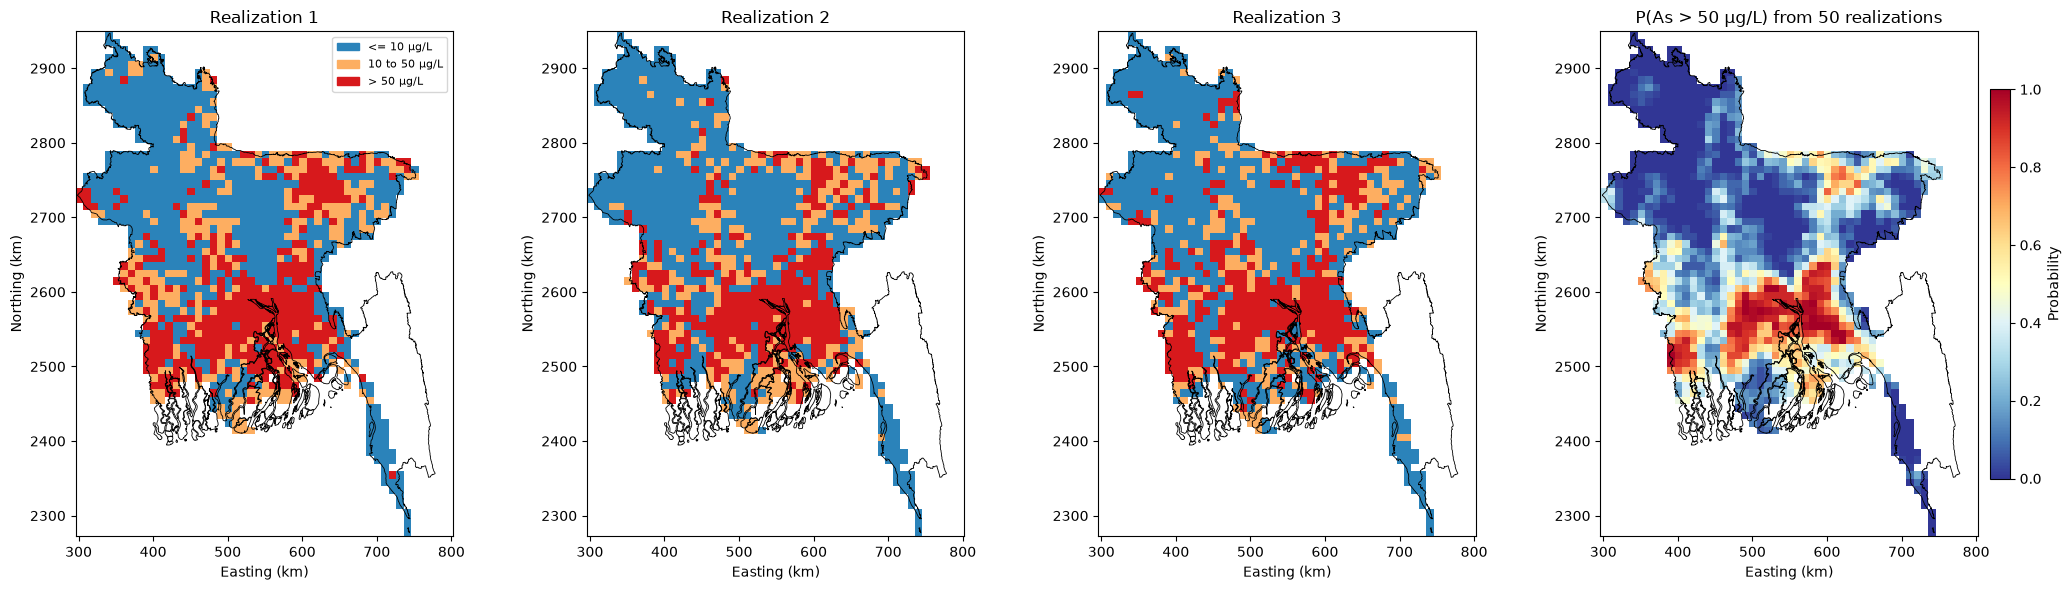

,limit_ug_L,mean_km2,p05_km2,p95_km2,mean_share_pct,IK_expected_km2
0,10.0,59934.0,57800.0,62555.0,47.0,60158.0
1,50.0,35112.0,33100.0,36900.0,27.0,35252.0


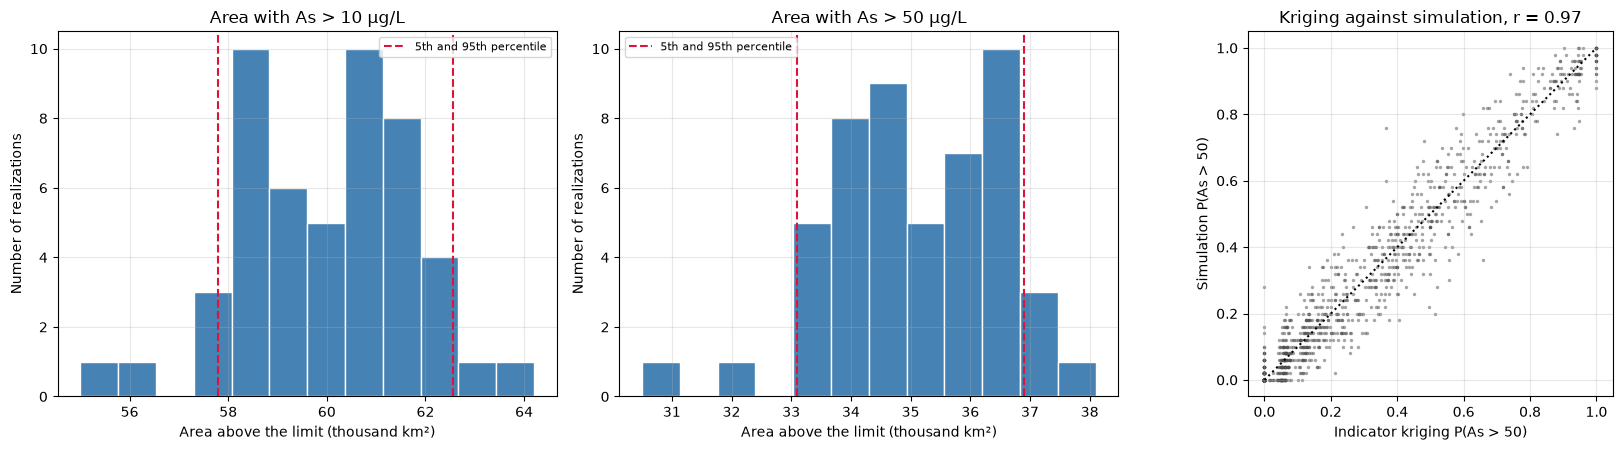

In [18]:
# Draw values on the coarse simulation grid, every second node of the 5 km grid.
def sim_raster(values):
    r = np.full((len(gy_u), len(gx_u)), np.nan)
    r[row[sim_nodes], col[sim_nodes]] = values
    return r[::2, ::2]

# Share of realizations above each regulatory limit.
sim_p50 = (sims > BD_LIMIT).mean(axis=0)
sim_p10 = (sims > WHO_LIMIT).mean(axis=0)

# Three example realizations, and the simulated probability of exceeding 50 µg/L.
fig, axes = plt.subplots(1, 4, figsize=(21, 6))
cmap_cls = ListedColormap(CLASS_COLORS)
norm_cls = BoundaryNorm([0, WHO_LIMIT, BD_LIMIT, 1e9], cmap_cls.N)
for ax, r in zip(axes[:3], [0, 1, 2]):
    ax.pcolormesh(gx_u[::2], gy_u[::2], sim_raster(sims[r]), cmap=cmap_cls, norm=norm_cls, shading="nearest")
    base_map(ax, f"Realization {r + 1}")
axes[0].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in CLASS_COLORS], CLASS_LABELS, loc="upper right", fontsize=8)
im = axes[3].pcolormesh(gx_u[::2], gy_u[::2], sim_raster(sim_p50), cmap="RdYlBu_r", vmin=0, vmax=1, shading="nearest")
base_map(axes[3], f"P(As > {BD_LIMIT:g} µg/L) from {N_SIM} realizations")
plt.colorbar(im, ax=axes[3], label="Probability", fraction=0.046, pad=0.03)
plt.tight_layout()
plt.show()

# Area above each limit in every realization, set next to the area implied by the kriged probabilities.
area50 = (sims > BD_LIMIT).sum(axis=1) * SIM_CELL_KM ** 2
area10 = (sims > WHO_LIMIT).sum(axis=1) * SIM_CELL_KM ** 2
total_area = sims.shape[1] * SIM_CELL_KM ** 2

area_sim_tbl = pd.DataFrame([
    {"limit_ug_L": lim, "mean_km2": a.mean(), "p05_km2": np.percentile(a, 5), "p95_km2": np.percentile(a, 95),
     "mean_share_pct": 100 * a.mean() / total_area,
     "IK_expected_km2": float(np.nansum(p[sim_nodes]) * SIM_CELL_KM ** 2)}
    for lim, a, p in [(WHO_LIMIT, area10, p10), (BD_LIMIT, area50, p50)]])
display(area_sim_tbl.round(0))

# Spread of that area across realizations, and a node-wise check against indicator kriging.
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, a, lim in zip(axes[:2], [area10, area50], [WHO_LIMIT, BD_LIMIT]):
    ax.hist(a / 1000, bins=12, color="steelblue", edgecolor="white")
    ax.axvline(np.percentile(a, 5) / 1000, color="crimson", ls="--", label="5th and 95th percentile")
    ax.axvline(np.percentile(a, 95) / 1000, color="crimson", ls="--")
    ax.set_xlabel("Area above the limit (thousand km²)")
    ax.set_ylabel("Number of realizations")
    ax.set_title(f"Area with As > {lim:g} µg/L")
    ax.legend(fontsize=8)
axes[2].scatter(p50[sim_nodes], sim_p50, s=6, c="0.3", alpha=0.5, linewidths=0)
axes[2].plot([0, 1], [0, 1], "k:")
axes[2].set_xlabel("Indicator kriging P(As > 50)")
axes[2].set_ylabel("Simulation P(As > 50)")
axes[2].set_title(f"Kriging against simulation, r = {np.corrcoef(p50[sim_nodes], sim_p50)[0, 1]:.2f}")
axes[2].set_aspect("equal")
plt.tight_layout()
plt.show()

**Reading the results.** The simulated maps are much noisier than the kriged probability map. This is what the large nugget implies: a real map of arsenic has safe and unsafe wells side by side even inside the high-risk belt. The pooled realizations reproduce the declustered target distribution to within about 0.02 at every cutoff, and the probability computed from the realizations agrees with indicator kriging (r = 0.97).

The area where a well would exceed 50 µg/L is about 35,100 km², with a 90% interval of 33,100 to 36,900 km² (27% of the mapped area). For 10 µg/L it is about 59,900 km² (57,800 to 62,600 km²). These figures are larger than the 29,500 km² of high-risk area in Section 9 because they answer a different question. The risk class counts cells where exceedance is more likely than not. The simulation counts the expected exceeding area, including the scattered unsafe wells inside uncertain and low-risk cells.

The intervals are narrow because the simulation is conditional on 3,146 wells and treats the variogram models and the target distribution as known. They describe interpolation uncertainty only.

## District priority list

The boundary file holds only the national outline, so each grid node is assigned to the district of its nearest shallow well. This is a Voronoi approximation of the district boundaries and is accurate enough for a ranking. Districts are ranked by the mean probability of exceeding the Bangladesh standard.

Districts: 61


,DIVISION,DISTRICT,area_km2,mean_P_above_10,mean_P_above_50,etype_As,high_risk_share_pct,n_wells,obs_pct_above_50
0,Chittagong,Chandpur,1775.0,0.99,0.95,357.14,100.00,53,98.11
1,Dhaka,Gopalganj,1525.0,0.99,0.93,248.78,100.00,34,94.12
2,Dhaka,Madaripur,975.0,0.92,0.90,259.47,100.00,27,92.59
3,Dhaka,Shariatpur,1300.0,0.94,0.83,233.25,100.00,40,80.00
4,Dhaka,Munshiganj,1050.0,0.88,0.82,233.03,92.86,45,84.44
5,Khulna,Satkhira,2900.0,0.85,0.67,164.15,72.41,51,74.51
6,Dhaka,Faridpur,2125.0,0.78,0.66,162.12,71.76,60,66.67
7,Chittagong,Comilla,3250.0,0.71,0.63,171.42,64.62,101,66.34
8,Chittagong,Noakhali,2200.0,0.87,0.63,164.39,53.41,43,79.07
9,Barisal,Barisal,2625.0,0.82,0.61,193.66,82.86,42,64.29


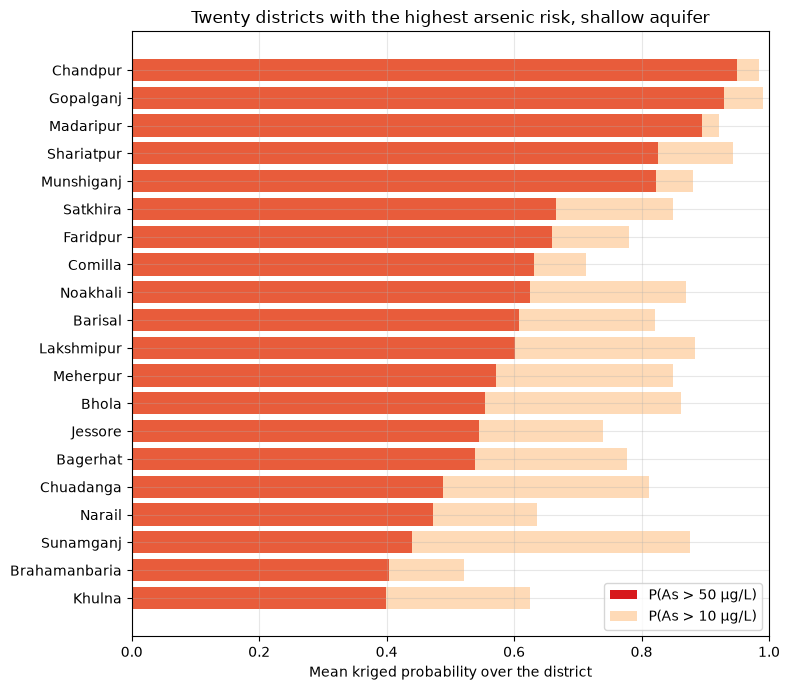

Districts with mean P(As > 50) >= 0.5: 15    below 0.1: 21


In [19]:
# Assign each mapped node to the district of the nearest shallow well.
nearest = cKDTree(xy).query(gxy)[1]
gtab = pd.DataFrame({
    "DISTRICT": shallow["DISTRICT"].to_numpy()[nearest],
    "DIVISION": shallow["DIVISION"].to_numpy()[nearest],
    "p10": p10, "p50": p50, "etype": etype, "risk50": risk50,
})[mapped]

# District means of the kriged probabilities, the E-type concentration, and the high-risk share.
district = (gtab.groupby(["DIVISION", "DISTRICT"])
                .agg(area_km2=("p50", lambda s: len(s) * CELL_KM ** 2),
                     mean_P_above_10=("p10", "mean"),
                     mean_P_above_50=("p50", "mean"),
                     etype_As=("etype", "mean"),
                     high_risk_share_pct=("risk50", lambda s: 100 * np.mean(s == 2)))
                .reset_index())
# Observed share of wells above 50 µg/L, joined for comparison with the mapped probability.
wells = (shallow.groupby("DISTRICT")["As"]
                .agg(n_wells="size", obs_pct_above_50=lambda s: 100 * (s > BD_LIMIT).mean())
                .reset_index())
district = district.merge(wells, on="DISTRICT", how="left").sort_values("mean_P_above_50", ascending=False).reset_index(drop=True)

print(f"Districts: {len(district)}")
display(district.head(15).round(2))

# The twenty districts with the highest mean probability of exceeding 50 µg/L.
top = district.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top["DISTRICT"], top["mean_P_above_50"], color="#d7191c", label="P(As > 50 µg/L)")
ax.barh(top["DISTRICT"], top["mean_P_above_10"], color="#fdae61", alpha=0.45, label="P(As > 10 µg/L)")
ax.set_xlim(0, 1)
ax.set_xlabel("Mean kriged probability over the district")
ax.set_title("Twenty districts with the highest arsenic risk, shallow aquifer")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Counts at the same 0.5 and 0.1 cuts used for the high-risk and low-risk classes.
n_high = int((district["mean_P_above_50"] >= 0.5).sum())
n_low = int((district["mean_P_above_50"] < 0.1).sum())
print(f"Districts with mean P(As > 50) >= 0.5: {n_high}    below 0.1: {n_low}")

**Reading the results.** Fifteen of 61 districts have a mean probability of at least 0.5 of exceeding the Bangladesh standard, and 21 are below 0.1. Chandpur, Gopalganj, Madaripur, Shariatpur and Munshiganj lead the list with mean probabilities above 0.8, and nearly all of their area is high risk. The kriged district means follow the observed share of wells above 50 µg/L closely, which is expected because every district has its own wells.

The value of kriging shows in districts with few wells. Bhola has only two shallow wells, both above the limit. The observed share is 100%, while the kriged mean is 0.55 because the estimate borrows from neighbouring districts and the indicator variogram.

## Is the deep aquifer a safe alternative?

Wells of 150 m or deeper are too few and too clustered for a national kriged map, so they are compared with the shallow kriged probability at the same locations. If a deep well is clean where the shallow aquifer is predicted to be contaminated, the deep aquifer is a real alternative at that location.

,n_deep_wells,median_As,pct_above_10,pct_above_50
shallow_risk,,,,
Low risk (P < 0.1),85,0.3,7.1,0.0
Uncertain (0.1 to 0.5),98,0.4,5.1,1.0
High risk (P >= 0.5),144,1.0,3.5,1.4


DIVISION
Barisal       197
Khulna         43
Chittagong     41
Dhaka          38
Sylhet          8


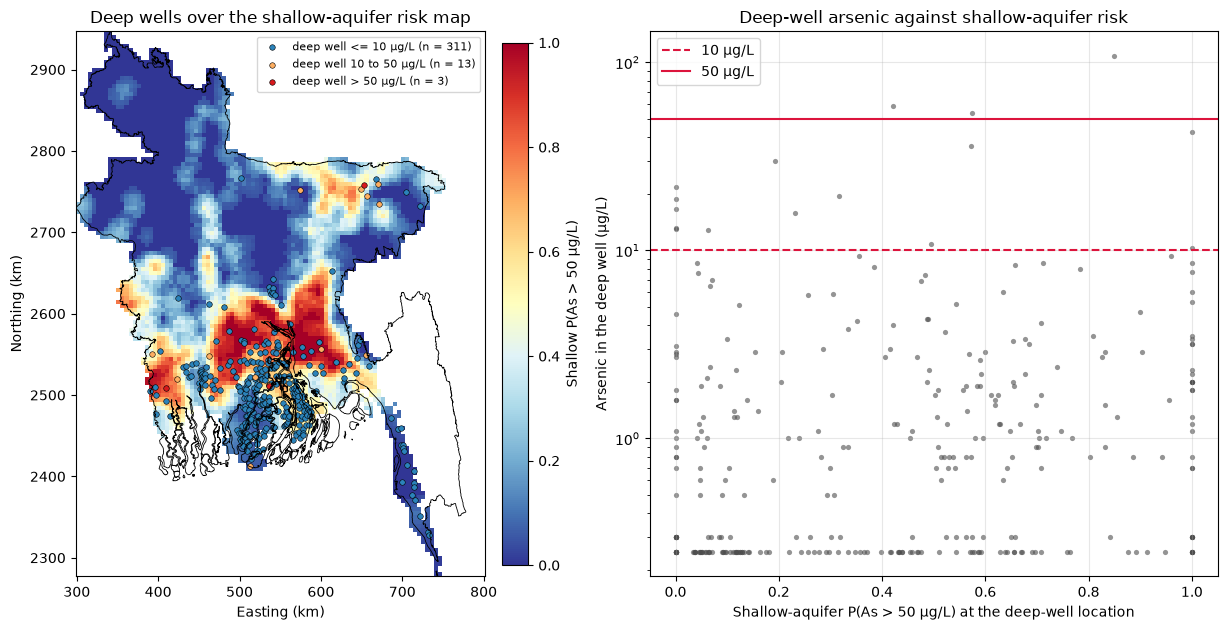

In [20]:
# Shallow-aquifer probability at each deep well, from the model fit on the shallow wells only.
dxy = deep[["x", "y"]].to_numpy(float)
dz = deep["As"].to_numpy(float)
p50_at_deep = np.clip(ik_full.predict(dxy, [BD_LIMIT], ivario_all)[BD_LIMIT], 0, 1)

# Deep-well exceedance rates, grouped by the shallow-aquifer risk class at the same location.
deep_tbl = pd.DataFrame({"shallow_P_above_50": p50_at_deep, "deep_As": dz})
deep_tbl["shallow_risk"] = pd.cut(deep_tbl["shallow_P_above_50"], RISK_BINS, labels=RISK_LABELS, include_lowest=True, right=False)
summary_deep = (deep_tbl.groupby("shallow_risk", observed=False)["deep_As"]
                .agg(n_deep_wells="size", median_As="median",
                     pct_above_10=lambda s: 100 * (s > WHO_LIMIT).mean(),
                     pct_above_50=lambda s: 100 * (s > BD_LIMIT).mean()))
display(summary_deep.round(1))
print(deep["DIVISION"].value_counts().to_string())

# Deep wells drawn on the shallow risk map, and deep-well arsenic against that probability.
fig, axes = plt.subplots(1, 2, figsize=(13, 6.4))
plot_raster(axes[0], p50, "Deep wells over the shallow-aquifer risk map", cmap="RdYlBu_r", vmin=0, vmax=1, label="Shallow P(As > 50 µg/L)")
dcls = pd.cut(deep["As"], CLASS_BINS, labels=CLASS_LABELS, include_lowest=True)
for lab, colr in zip(CLASS_LABELS, CLASS_COLORS):
    m = (dcls == lab).to_numpy()
    axes[0].scatter(dxy[m, 0], dxy[m, 1], s=16, c=colr, edgecolors="k", linewidths=0.4, label=f"deep well {lab} (n = {m.sum()})")
axes[0].legend(loc="upper right", fontsize=8)

axes[1].scatter(p50_at_deep, dz, s=14, c="0.3", alpha=0.6, linewidths=0)
axes[1].axhline(WHO_LIMIT, color="crimson", ls="--", label="10 µg/L")
axes[1].axhline(BD_LIMIT, color="crimson", ls="-", label="50 µg/L")
axes[1].set_yscale("log")
axes[1].set_xlabel("Shallow-aquifer P(As > 50 µg/L) at the deep-well location")
axes[1].set_ylabel("Arsenic in the deep well (µg/L)")
axes[1].set_title("Deep-well arsenic against shallow-aquifer risk")
axes[1].legend()
plt.tight_layout()
plt.show()

**Reading the results.** Of the 327 deep wells, 144 are in locations where the shallow aquifer is high risk. Only 1.4% of those exceed 50 µg/L and 3.5% exceed 10 µg/L. The deep aquifer was therefore a safe alternative in most of the worst-affected area at the time of the survey.

Two limits apply. Deep wells are concentrated in the coastal south (197 of 327 are in Barisal division), so the evidence is weak elsewhere. The survey is also a snapshot from 1998 and 1999 and says nothing about whether heavy pumping of the deep aquifer keeps it clean.

## Summary of results

In [21]:
# At each limit, the method with the lowest Brier score on the held-out wells.
best = val_tbl.loc[val_tbl.groupby("limit_ug_L")["Brier"].idxmin(), ["limit_ug_L", "method", "AUC", "Brier_skill", "false_safe_rate"]]
# Headline numbers from the cleaning, the variogram, the maps, and the simulations.
summary = pd.DataFrame([
    ("Shallow wells used", f"{len(z):,}"),
    ("Samples at the detection limit", f"{100 * (z <= AS_FLOOR).mean():.0f}%"),
    ("Declustered share above 10 µg/L", f"{100 * np.average(z > WHO_LIMIT, weights=w_declus):.0f}%"),
    ("Declustered share above 50 µg/L", f"{100 * np.average(z > BD_LIMIT, weights=w_declus):.0f}%"),
    ("Nugget share, log As variogram", f"{100 * float(fit_tbl.loc[fit_tbl.model == best_model, 'nugget_share'].iloc[0]):.0f}%"),
    ("Best test Brier score at 10 µg/L", f"{best.iloc[0]['method']} (AUC {best.iloc[0]['AUC']:.2f})"),
    ("Best test Brier score at 50 µg/L", f"{best.iloc[1]['method']} (AUC {best.iloc[1]['AUC']:.2f})"),
    ("Mapped area", f"{mapped.sum() * CELL_KM ** 2:,.0f} km²"),
    ("High-risk area at 50 µg/L (P >= 0.5)", f"{np.sum(risk50 == 2) * CELL_KM ** 2:,.0f} km²"),
    ("Simulated area above 50 µg/L, 90% interval", f"{np.percentile(area50, 5):,.0f} to {np.percentile(area50, 95):,.0f} km²"),
    ("Simulated area above 10 µg/L, 90% interval", f"{np.percentile(area10, 5):,.0f} to {np.percentile(area10, 95):,.0f} km²"),
    ("Districts with mean P(As > 50) >= 0.5", f"{n_high} of {len(district)}"),
    ("Deep wells above 50 µg/L", f"{100 * (dz > BD_LIMIT).mean():.1f}% of {len(dz)}"),
], columns=["Result", "Value"])
display(summary)

,Result,Value
0,Shallow wells used,"3,146"
1,Samples at the detection limit,28%
2,Declustered share above 10 µg/L,46%
3,Declustered share above 50 µg/L,26%
4,"Nugget share, log As variogram",42%
5,Best test Brier score at 10 µg/L,Indicator kriging (AUC 0.88)
6,Best test Brier score at 50 µg/L,Disjunctive kriging (AUC 0.90)
7,Mapped area,"128,025 km²"
8,High-risk area at 50 µg/L (P >= 0.5),"29,500 km²"
9,"Simulated area above 50 µg/L, 90% interval","33,100 to 36,900 km²"


## Conclusions and limitations

**What the analysis shows**

1. About 46% of shallow wells exceed the WHO guideline and 26% exceed the Bangladesh standard after declustering. Contamination is regional: the south, the south-east and the Sylhet basin carry most of the risk.
2. Short-range variability is large. The nugget is about 42% of the variance of log arsenic and more than half of the indicator variance. Maps can rank areas, but every well still has to be tested.
3. Indicator and disjunctive kriging give better-calibrated exceedance probabilities than lognormal kriging. All three rank wells about equally (AUC 0.87 to 0.90).
4. Phosphorus and iron predict exceedance almost as well as a quarter-density arsenic survey. Markov-Bayes kriging added nothing beyond the calibrated soft probability in this test.
5. The deep aquifer was almost free of arsenic above 50 µg/L, including under the high-risk shallow areas.

**Limitations**

- The data are from 1998 and 1999. The maps describe the situation at that time.
- Values below the detection limit are fixed at 0.25 µg/L. This affects lognormal and disjunctive kriging, but not indicator kriging at cutoffs of 1 µg/L and above.
- The validation uses a random split. Because wells are spatially correlated, the scores are optimistic for areas far from any well (Exercise 1).
- All models are isotropic and stationary. The directional variograms suggest mild anisotropy.
- The district table uses nearest-well assignment, not official district boundaries.
- The simulation intervals do not include uncertainty in the variogram models or the target distribution.
- The maps give the probability for a well, not the population exposed. Exposure needs population and well-use data.

## Exercises

1. Repeat Sections 6 and 7 with a spatially blocked split (hold out whole 50 km blocks) in place of the random split. How much do the AUC and the false-safe rate change?
2. Lower the high-risk rule from $P \ge 0.5$ to $P \ge 0.2$. How does the false-safe rate on the test wells respond, and how much larger is the high-risk area?
3. Add an anisotropy angle and ratio to `IndicatorKriging` based on the directional variograms in Section 4. Does the Brier score improve?
4. Replace the 150 m depth split with three classes (below 50 m, 50 to 150 m, 150 m and deeper) and map the first two separately.
5. Use `kt3d` with well depth as the third coordinate and compare the predicted depth profile at three locations with the split-aquifer result.
6. Run `sisim` on the full 5 km grid with 100 realizations and check whether the 90% interval of the affected area changes.

## References

- BGS and DPHE (2001). *Arsenic contamination of groundwater in Bangladesh.* Kinniburgh, D. G. and Smedley, P. L. (eds). British Geological Survey Technical Report WC/00/19. British Geological Survey, Keyworth.
- Deutsch, C. V. and Journel, A. G. (1998). *GSLIB: Geostatistical Software Library and User's Guide*, 2nd ed. Oxford University Press.
- Gaus, I., Kinniburgh, D. G., Talbot, J. C. and Webster, R. (2003). Geostatistical analysis of arsenic concentration in groundwater in Bangladesh using disjunctive kriging. *Environmental Geology*, 44, 939-948.
- Goovaerts, P. (1997). *Geostatistics for Natural Resources Evaluation.* Oxford University Press.
- Zhu, H. and Journel, A. G. (1993). Formatting and integrating soft data: stochastic imaging via the Markov-Bayes algorithm. In Soares, A. (ed.), *Geostatistics Tróia '92*, Kluwer, 1-12.